## EN3160 Assignment 02
### Fitting and Alignment

**Name:** Rahman MFA  
**Index number:** 230507R  
**Repository:** [EN3160 Image Processing and Machine Vision](https://github.com/Abdul-Rahman-bme/EN3160-Image-processing-and-Machine-Vision)


In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import maximum_filter
from scipy.optimize import minimize

IMAGE_DIR = Path("images/a2images")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("OpenCV version:", cv.__version__)
print("NumPy version:", np.__version__)
print("Image folder:", IMAGE_DIR.resolve())
print("Output folder:", OUTPUT_DIR.resolve())

OpenCV version: 5.0.0
NumPy version: 2.4.6
Image folder: D:\Abdul Rahman\Engineering_UOM\.Sem 5\EN3160 - Image Processing and Computer Vision\EN3160-Image-processing-and-Machine-Vision\Assignment_02\images\a2images
Output folder: D:\Abdul Rahman\Engineering_UOM\.Sem 5\EN3160 - Image Processing and Computer Vision\EN3160-Image-processing-and-Machine-Vision\Assignment_02\outputs


### Q1 — Sunflower blob detection using LoG

Image dimensions (height, width): (360, 360)


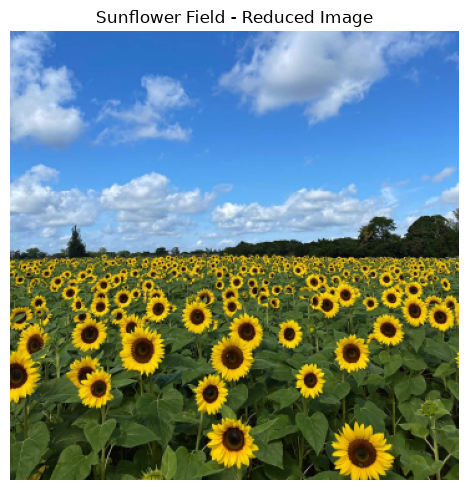

In [3]:
sunflower_path = IMAGE_DIR / "the_berry_farms_sunflower_field.jpeg"
sunflower = cv.imread(str(sunflower_path), cv.IMREAD_REDUCED_COLOR_4)

if sunflower is None:
    raise FileNotFoundError(f"Could not load image: {sunflower_path.resolve()}")

sunflower_rgb = cv.cvtColor(sunflower, cv.COLOR_BGR2RGB)
sunflower_gray = cv.cvtColor(sunflower, cv.COLOR_BGR2GRAY)

print("Image dimensions (height, width):", sunflower_gray.shape)

plt.figure(figsize=(8, 5))
plt.imshow(sunflower_rgb)
plt.title("Sunflower Field - Reduced Image")
plt.axis("off")
plt.tight_layout()
plt.show()

In [6]:
# Build the scale-normalized LoG response stack.
# Each slice corresponds to one sigma value.
sigmas = np.linspace(1.5, 16.0, 30, dtype=np.float32)
gray_float = sunflower_gray.astype(np.float32) / 255.0

response_list = []
for sigma in sigmas:
    smoothed = cv.GaussianBlur(
        gray_float, (0, 0),
        sigmaX=float(sigma), sigmaY=float(sigma)
    )
    laplacian = cv.Laplacian(smoothed, cv.CV_32F, ksize=1)
    response_list.append((float(sigma) ** 2) * np.abs(laplacian))

responses = np.stack(response_list, axis=0)

print(f"Scales: {len(sigmas)}")
print(f"Sigma range: {sigmas[0]:.1f}–{sigmas[-1]:.1f} pixels")
print("Response stack shape:", responses.shape)

Scales: 30
Sigma range: 1.5–16.0 pixels
Response stack shape: (30, 360, 360)


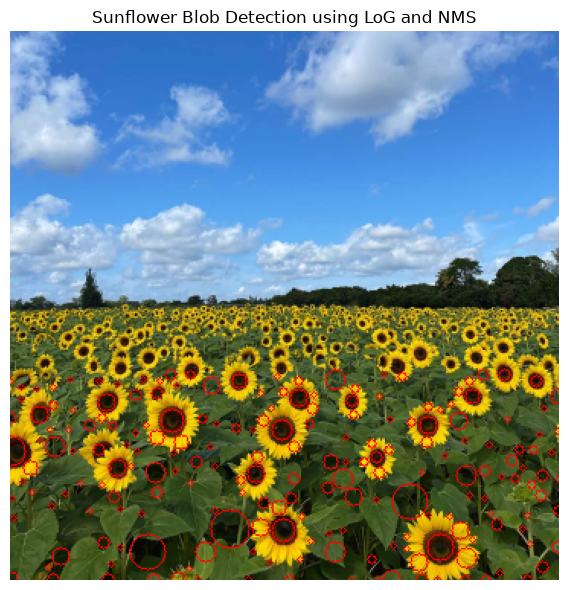

Maximum field response: 0.381031
Threshold: 0.057155
Candidates before NMS: 418
Detections after NMS: 221
Strongest detections (x, y, sigma, response):
[(303, 239, 4.0, 0.3810310363769531), (224, 242, 3.0, 0.37745198607444763), (240, 279, 3.5, 0.37730783224105835), (345, 229, 3.5, 0.37645208835601807), (150, 229, 4.0, 0.3671875), (189, 240, 4.5, 0.36296725273132324), (106, 255, 6.0, 0.3627891540527344), (161, 290, 4.5, 0.3617174029350281), (63, 243, 4.5, 0.35576391220092773), (178, 261, 5.5, 0.3515820801258087)]
Largest circles (x, y, radius in pixels, sigma):
(144, 326), radius=13.44, sigma=9.50
(90, 341), radius=12.73, sigma=9.00
(262, 308), radius=12.02, sigma=8.50
(0, 275), radius=10.61, sigma=7.50
(282, 338), radius=9.90, sigma=7.00
(106, 255), radius=8.49, sigma=6.00
(179, 327), radius=8.49, sigma=6.00
(23, 322), radius=8.49, sigma=6.00
(178, 261), radius=7.78, sigma=5.50
(299, 345), radius=7.78, sigma=5.50


In [7]:
# Select the lower part of the image, where most flowers are visible.
field_start = min(225, sunflower_gray.shape[0] - 1)
field_responses = responses[:, field_start:, :]

# Find local maxima across scale and image position.
local_max = maximum_filter(field_responses, size=(3, 9, 9))
threshold = 0.15 * field_responses.max()

s, y, x = np.where(
    (field_responses == local_max) &
    (field_responses > threshold)
)

candidates = [
    (int(xi), int(yi + field_start), float(sigmas[si]),
     float(field_responses[si, yi, xi]))
    for si, yi, xi in zip(s, y, x)
]
candidates.sort(key=lambda blob: blob[3], reverse=True)

# Keep the strongest candidate when detections overlap.
blobs = []
for x, y, sigma, score in candidates:
    radius = np.sqrt(2) * sigma
    if all(
        np.hypot(x - bx, y - by) >= max(8, radius + np.sqrt(2) * bs)
        for bx, by, bs, _ in blobs
    ):
        blobs.append((x, y, sigma, score))

result = sunflower_rgb.copy()
for x, y, sigma, score in blobs[:200]:
    cv.circle(result, (x, y), max(2, int(np.sqrt(2) * sigma)),
              (255, 0, 0), 1)

plt.figure(figsize=(8, 6))
plt.imshow(result)
plt.title("Sunflower Blob Detection using LoG and NMS")
plt.axis("off")
plt.tight_layout()
plt.show()

print(f"Maximum field response: {field_responses.max():.6f}")
print(f"Threshold: {threshold:.6f}")
print(f"Candidates before NMS: {len(candidates)}")
print(f"Detections after NMS: {len(blobs)}")
print("Strongest detections (x, y, sigma, response):")
print(blobs[:10])

print("Largest circles (x, y, radius in pixels, sigma):")
for x, y, sigma, _ in sorted(blobs, key=lambda blob: blob[2], reverse=True)[:10]:
    print(f"({x}, {y}), radius={np.sqrt(2) * sigma:.2f}, sigma={sigma:.2f}")

The LoG response highlights regions whose intensity changes resemble a blob. Multiplying the Laplacian response by sigma squared helps compare detections across different scales. The local-maximum step selects strong responses in both image position and scale.

I restricted the search to the lower part of the image to reduce responses from the sky and distant trees. This is a practical choice for this image, but it may miss flowers near the horizon. The detector can also respond to leaves, petals, and other round-looking details, so the result should be interpreted as a list of candidates rather than an exact sunflower count. The table is sorted by response strength, and the plotted image shows only the first 40 candidates for readability.

### Q2 — RANSAC line and circle fitting

In [8]:

# Q2 - Generate the noisy point set
from scipy.optimize import minimize
from matplotlib.patches import Circle

np.random.seed(0)

N = 100
half_n = N // 2

# Generate noisy points around a circle.
r_gt = 10
x0_gt, y0_gt = 2, 3
noise_c = r_gt / 16

t = np.random.uniform(0, 2 * np.pi, half_n)
n = noise_c * np.random.randn(half_n)
X_circ = np.column_stack((
    x0_gt + (r_gt + n) * np.cos(t),
    y0_gt + (r_gt + n) * np.sin(t)
))

# Generate noisy points around a straight line.
m_gt, b_gt = -1, 2
x_line = np.linspace(-12, 12, half_n)
y_line = m_gt * x_line + b_gt + np.random.randn(half_n)
X_line = np.column_stack((x_line, y_line))

X = np.vstack((X_circ, X_line))
print("Total number of points:", len(X))

Total number of points: 100


In [9]:

# Fit a line from a pair of points
def line_from_pair(p1, p2):
    v = p2 - p1
    length = np.linalg.norm(v)
    if length < 1e-8:
        return None

    normal = np.array([-v[1], v[0]]) / length
    d = normal @ p1
    return np.array([normal[0], normal[1], d])


def line_error(points, model):
    return np.abs(points @ model[:2] - model[2])


# Refine the line with total least squares
def fit_tls_line(points):
    centre = points.mean(axis=0)
    _, _, vh = np.linalg.svd(points - centre, full_matrices=False)
    direction = vh[0]
    normal = np.array([-direction[1], direction[0]])
    return np.array([normal[0], normal[1], normal @ centre])


# RANSAC settings
line_threshold = 1.5
min_line_inliers = 35
best_line_count = 0

for _ in range(2000):
    ids = np.random.choice(len(X), 2, replace=False)
    model = line_from_pair(X[ids[0]], X[ids[1]])
    if model is None:
        continue

    inliers = line_error(X, model) <= line_threshold
    count = inliers.sum()

    if count >= min_line_inliers and count > best_line_count:
        best_line_count = count
        best_line_sample_model = model
        best_line_sample = X[ids].copy()

# Refine the best line using its inliers
line_inliers = line_error(X, best_line_sample_model) <= line_threshold
best_fit_line = fit_tls_line(X[line_inliers])
line_inliers = line_error(X, best_fit_line) <= line_threshold
best_fit_line = fit_tls_line(X[line_inliers])
line_inliers = line_error(X, best_fit_line) <= line_threshold

a, b, d = best_fit_line
print(f"Line inliers: {line_inliers.sum()}")
print(f"Best-fit line: {a:.3f}x + {b:.3f}y = {d:.3f}")
print(f"Normal vector length: {np.linalg.norm([a, b]):.3f}")

Line inliers: 54
Best-fit line: 0.721x + 0.693y = 1.572
Normal vector length: 1.000


In [10]:

# Remove the line inliers before fitting the circle
remaining = X[~line_inliers]


def circle_from_three(points):
    p1, p2, p3 = points
    A = 2*np.vstack((p2-p1, p3-p1))
    rhs = np.array([p2@p2-p1@p1, p3@p3-p1@p1])

    if abs(np.linalg.det(A)) < 1e-8:
        return None

    cx, cy = np.linalg.solve(A, rhs)
    r = np.linalg.norm(p1 - [cx, cy])
    return np.array([cx, cy, r])


def circle_error(points, model):
    return np.abs(np.linalg.norm(points-model[:2], axis=1) - model[2])


# Find a circle using RANSAC
circle_threshold = 1.25
min_circle_inliers = 30
best_circle_count = 0

for _ in range(2000):
    ids = np.random.choice(len(remaining), 3, replace=False)
    sample = remaining[ids]
    model = circle_from_three(sample)
    if model is None:
        continue

    inliers = circle_error(remaining, model) <= circle_threshold
    count = inliers.sum()

    if count >= min_circle_inliers and count > best_circle_count:
        best_circle_count = count
        best_circle_sample_model = model
        best_circle_sample = sample.copy()

# Refine the circle using the inliers
circle_inliers = circle_error(
    remaining, best_circle_sample_model
) <= circle_threshold
circle_points = remaining[circle_inliers]


def circle_loss(params, points):
    errors = np.linalg.norm(points-params[:2], axis=1) - params[2]
    return np.sum(errors**2)


opt = minimize(
    circle_loss, best_circle_sample_model, args=(circle_points,),
    bounds=[(None, None), (None, None), (1e-6, None)]
)
if not opt.success:
    print('Warning: circle refinement did not converge:', opt.message)
best_fit_circle = opt.x
circle_inliers = circle_error(remaining, best_fit_circle) <= circle_threshold
circle_points = remaining[circle_inliers]

# Show the final estimates
cx, cy, radius = best_fit_circle
print(f"Circle inliers: {circle_inliers.sum()}")
print(f"Centre: ({cx:.3f}, {cy:.3f})")
print(f"Radius: {radius:.3f}")

Circle inliers: 44
Centre: (1.949, 2.988)
Radius: 9.892


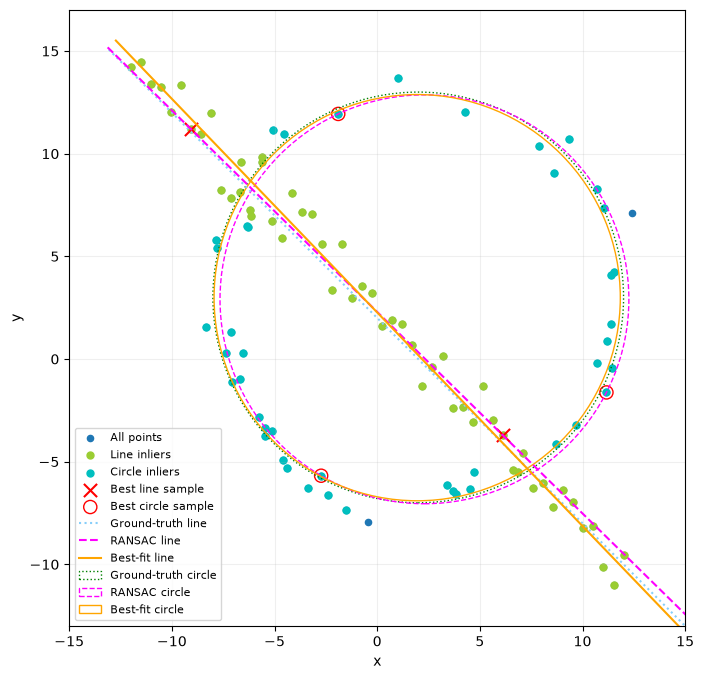

In [11]:

# Draw the fitted models and compare them with the original points
def draw_line(ax, model, label, color, style="-"):
    a, b, d = model
    normal = np.array([a, b])
    point = d * normal
    direction = np.array([-b, a])
    t = np.linspace(-20, 20, 100)
    line = point + t[:, None]*direction
    ax.plot(line[:, 0], line[:, 1], color=color,
            linestyle=style, label=label)


def draw_circle(ax, model, label, color, style="-"):
    cx, cy, r = model
    ax.add_patch(Circle((cx, cy), r, fill=False,
                        color=color, linestyle=style, label=label))


fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(X[:, 0], X[:, 1], s=20, label="All points")
ax.scatter(X[line_inliers, 0], X[line_inliers, 1],
           s=25, color="yellowgreen", label="Line inliers")
ax.scatter(circle_points[:, 0], circle_points[:, 1],
           s=25, color="c", label="Circle inliers")

ax.scatter(best_line_sample[:, 0], best_line_sample[:, 1],
           marker="x", s=90, color="red", label="Best line sample")
ax.scatter(best_circle_sample[:, 0], best_circle_sample[:, 1],
           marker="o", s=90, facecolors="none",
           edgecolors="red", label="Best circle sample")

# Sample-based and refined lines
line_gt = np.array([1/np.sqrt(2), 1/np.sqrt(2), 2/np.sqrt(2)])
draw_line(ax, line_gt, "Ground-truth line", "lightskyblue", ":")
draw_line(ax, best_line_sample_model, "RANSAC line", "magenta", "--")
draw_line(ax, best_fit_line, "Best-fit line", "orange")

# Sample-based and refined circles
draw_circle(ax, [x0_gt, y0_gt, r_gt],
            "Ground-truth circle", "green", ":")
draw_circle(ax, best_circle_sample_model,
            "RANSAC circle", "magenta", "--")
draw_circle(ax, best_fit_circle, "Best-fit circle", "orange")

ax.set_xlim(-15, 15)
ax.set_ylim(-13, 17)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, alpha=0.2)
ax.legend(fontsize=8)
plt.show()


The line is fitted first so that its points do not interfere with circle fitting. RANSAC repeatedly tests a small random sample and keeps the model supported by the largest suitable group of points. I then refine the line using its inliers. After removing those points, the same general idea is used to find the circle, followed by a least-squares refinement.

The fitted values should be close to the values used to generate the synthetic data, but noise means they will not necessarily match exactly.

### Q3 — Homography and image compositing

Flag size: (960, 1920, 3)
Building size: (768, 1024, 3)


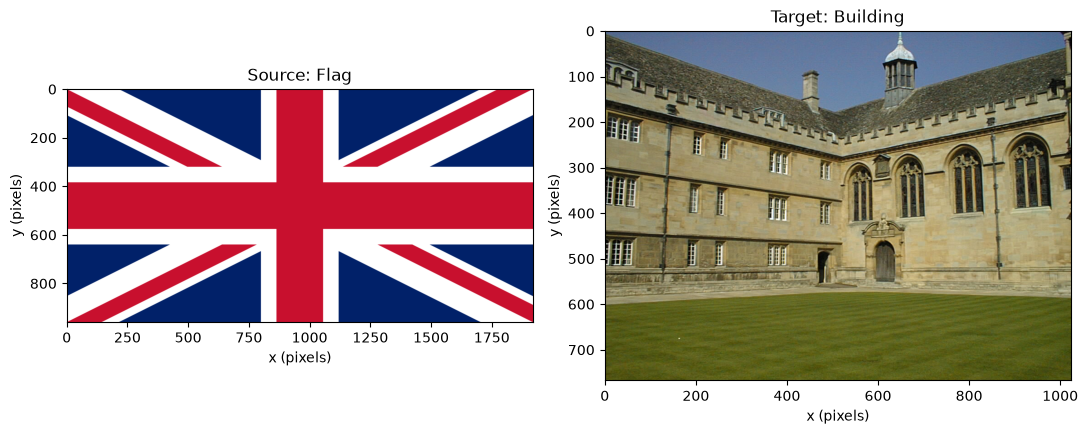

In [12]:

# Q3 - Load the flag and building images
flag = cv.imread(str(IMAGE_DIR / "flag.png"))
building = cv.imread(str(IMAGE_DIR / "wadham.jpg"))

if flag is None or building is None:
    raise FileNotFoundError("Check the image filenames and folder paths.")

flag_rgb = cv.cvtColor(flag, cv.COLOR_BGR2RGB)
building_rgb = cv.cvtColor(building, cv.COLOR_BGR2RGB)

print("Flag size:", flag.shape)
print("Building size:", building.shape)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(flag_rgb)
ax[0].set_title("Source: Flag")
ax[1].imshow(building_rgb)
ax[1].set_title("Target: Building")

for a in ax:
    a.set_xlabel("x (pixels)")
    a.set_ylabel("y (pixels)")

plt.tight_layout()
plt.show()


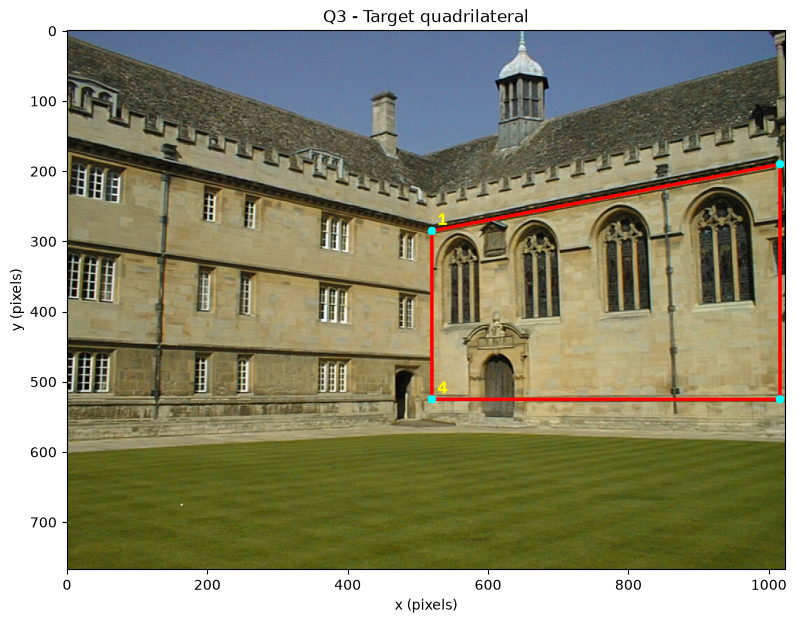

In [13]:
# Q3 - Select the target quadrilateral on the building

building_h, building_w = building.shape[:2]

dst_pts = np.float32([
    [520, 285],                 # Top-left
    [building_w - 8, 190],      # Top-right
    [building_w - 8, 525],      # Bottom-right
    [520, 525]                  # Bottom-left
])

preview = building_rgb.copy()

cv.polylines(
    preview,
    [dst_pts.astype(np.int32)],
    True,
    (255, 0, 0),
    3
)

for i, (x, y) in enumerate(dst_pts, start=1):
    cv.circle(preview, (int(x), int(y)), 6, (0, 255, 255), -1)
    cv.putText(
        preview, str(i), (int(x) + 8, int(y) - 8),
        cv.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 0), 2
    )

plt.figure(figsize=(10, 7))
plt.imshow(preview)
plt.title("Q3 - Target quadrilateral")
plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
plt.show()

Homography matrix:
[[ 1.08327565e-01  6.94694333e-17  5.20000000e+02]
 [-7.75823851e-02  2.50260688e-01  2.85000000e+02]
 [-1.47775972e-04  9.04549912e-20  1.00000000e+00]]


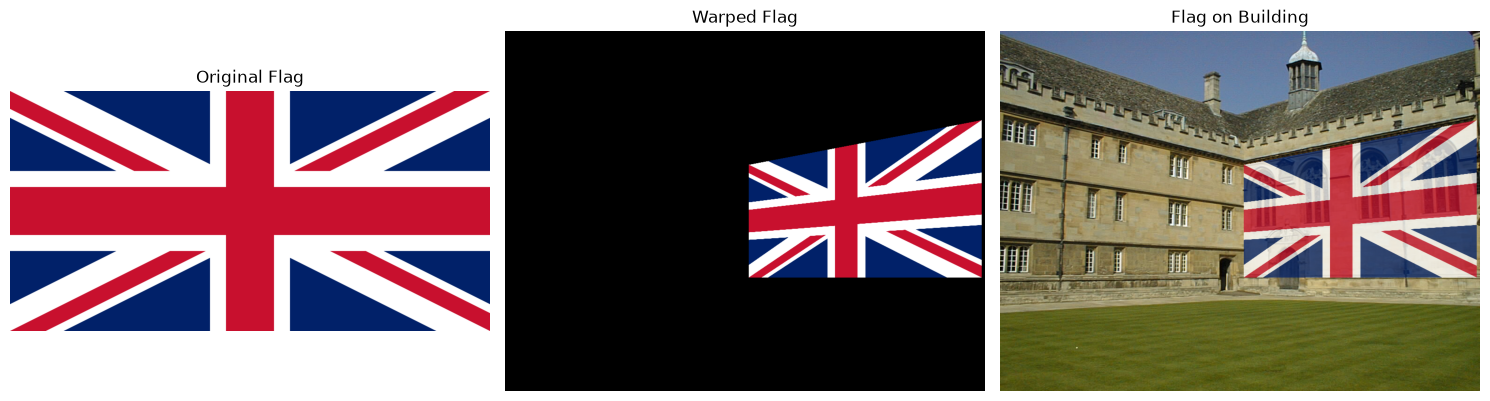

True

In [14]:
# Q3 - Calculate homography and warp the flag

flag_h, flag_w = flag.shape[:2]

# Four corners of the original flag
src_pts = np.float32([
    [0, 0],
    [flag_w - 1, 0],
    [flag_w - 1, flag_h - 1],
    [0, flag_h - 1]
])

# Map the flag corners to the building corners
H, status = cv.findHomography(src_pts, dst_pts)

if H is None:
    raise ValueError("Could not calculate the homography.")

print("Homography matrix:")
print(H)

# Warp the flag into the building image
warped_flag = cv.warpPerspective(
    flag, H, (building_w, building_h)
)

# Warp a mask so we know which pixels belong to the flag
flag_mask = np.full((flag_h, flag_w), 255, dtype=np.uint8)

warped_mask = cv.warpPerspective(
    flag_mask, H, (building_w, building_h),
    flags=cv.INTER_NEAREST
)

mask = warped_mask > 0

# Blend the flag with the original building
alpha = 0.75
result = building.copy()

result[mask] = cv.addWeighted(
    warped_flag[mask], alpha,
    building[mask], 1 - alpha, 0
)

# Display the results
warped_rgb = cv.cvtColor(warped_flag, cv.COLOR_BGR2RGB)
result_rgb = cv.cvtColor(result, cv.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(flag_rgb)
ax[0].set_title("Original Flag")

ax[1].imshow(warped_rgb)
ax[1].set_title("Warped Flag")

ax[2].imshow(result_rgb)
ax[2].set_title("Flag on Building")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

# Save the composite for later use in the report
cv.imwrite(
    str(OUTPUT_DIR / "q3_flag_on_right_facade.png"),
    result
)

Results and discussion      
The four source corners are mapped to the selected points on the building using a homography. A mask keeps the warped image inside the chosen quadrilateral, while blending lets some of the original building detail remain visible.

The result depends on choosing the corner points carefully and assumes the target surface is approximately planar. A homography does not automatically account for objects that should appear in front of the projected image.

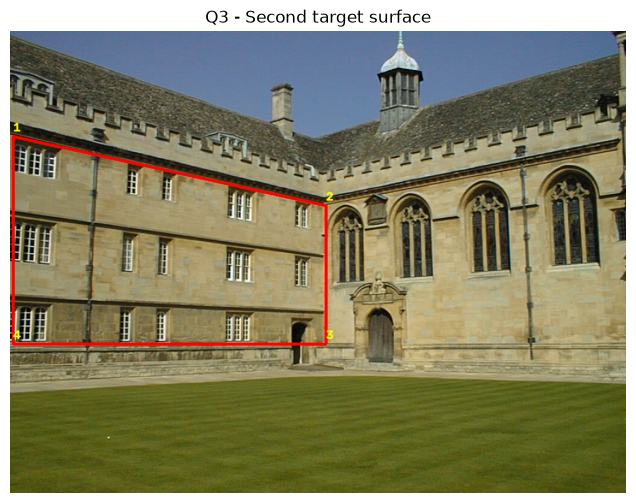

In [21]:

# Q3 - Select another surface for the second example

# Approximate corners of the left building façade
dst_pts2 = np.float32([
    [5, 175],    # Top-left
    [525, 290],   # Top-right
    [525, 520],   # Bottom-right
    [5, 520]     # Bottom-left
])


# Load the building image
building_bgr = cv.imread(str(IMAGE_DIR / "wadham.jpg"))

if building_bgr is None:
    raise FileNotFoundError("Could not load wadham.jpg. Check IMAGE_DIR.")

building_rgb = cv.cvtColor(building_bgr, cv.COLOR_BGR2RGB)

# Draw the selected quadrilateral
preview2 = building_rgb.copy()

cv.polylines(
    preview2,
    [dst_pts2.astype(np.int32)],
    True,
    (255, 0, 0),
    3
)

for i, (x, y) in enumerate(dst_pts2, 1):
    cv.putText(
        preview2, str(i),
        (int(x), int(y) - 8),
        cv.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 0),
        2
    )

plt.figure(figsize=(9, 6))
plt.imshow(preview2)
plt.title("Q3 - Second target surface")
plt.axis("off")
plt.show()


In [24]:

# Q3 - Warp the sunflower image onto the building

sunflower = cv.imread(
    str(IMAGE_DIR / "the_berry_farms_sunflower_field.jpeg")
)
building = cv.imread(str(IMAGE_DIR / "wadham.jpg"))

# Four corners of the sunflower image
h, w = sunflower.shape[:2]
src_pts2 = np.float32([
    [0, 0], [w-1, 0],
    [w-1, h-1], [0, h-1]
])

# Corresponding corners on the building façade
dst_pts2 = np.float32([
    [5, 175], [525, 290],
    [525, 520], [5, 520]
])

# Map the source corners to the selected wall
H2 = cv.getPerspectiveTransform(src_pts2, dst_pts2)

warped2 = cv.warpPerspective(
    sunflower, H2,
    (building.shape[1], building.shape[0])
)

print("Homography matrix:\n", H2)


Homography matrix:
 [[5.43780403e-01 0.00000000e+00 5.00000000e+00]
 [1.80681028e-01 2.39749826e-01 1.75000000e+02]
 [3.47463516e-04 0.00000000e+00 1.00000000e+00]]


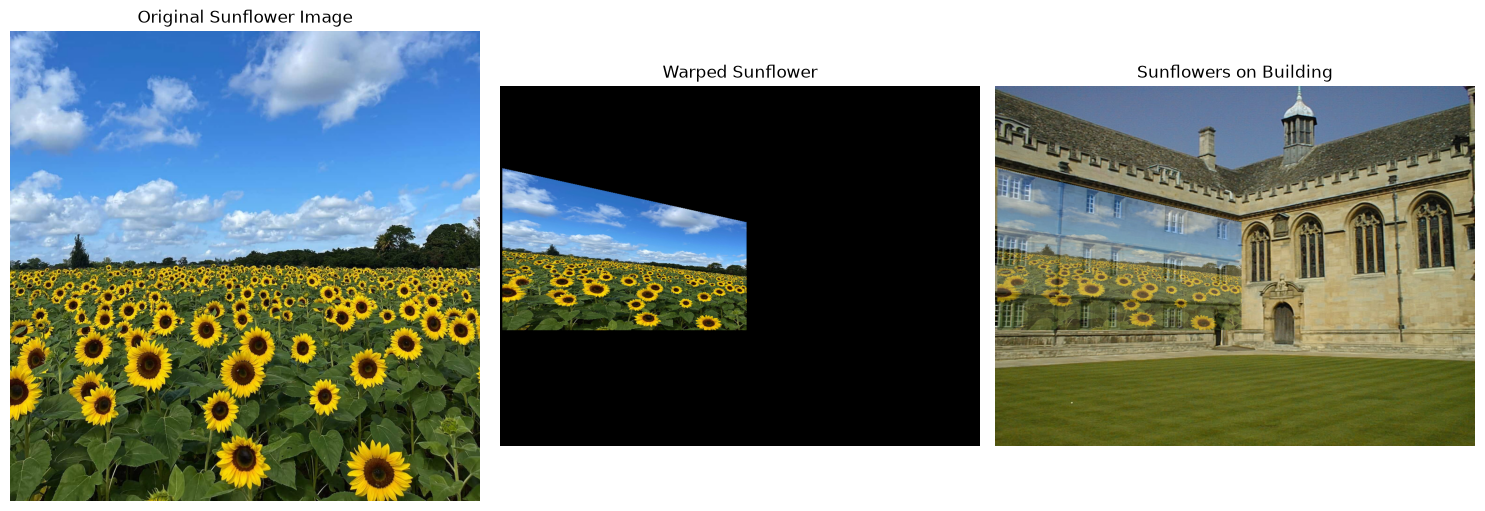

True

In [25]:

# Keep the warped image only inside the selected quadrilateral
mask2 = np.zeros(building.shape[:2], dtype=np.uint8)
cv.fillConvexPoly(mask2, dst_pts2.astype(np.int32), 255)

# Blend the sunflower image with the original wall
blend2 = cv.addWeighted(building, 0.45, warped2, 0.55, 0)

result2 = building.copy()
result2[mask2 == 255] = blend2[mask2 == 255]

# Display the result
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(cv.cvtColor(sunflower, cv.COLOR_BGR2RGB))
ax[0].set_title("Original Sunflower Image")

ax[1].imshow(cv.cvtColor(warped2, cv.COLOR_BGR2RGB))
ax[1].set_title("Warped Sunflower")

ax[2].imshow(cv.cvtColor(result2, cv.COLOR_BGR2RGB))
ax[2].set_title("Sunflowers on Building")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

cv.imwrite(str(OUTPUT_DIR / "q3_sunflower_on_building.png"), result2)


**Discussion**

The second example places the sunflower-field image on another part of the building. The four destination points define the target region, and cv.getPerspectiveTransform() calculates the mapping. The mask limits the composite to that region.

This shows how perspective can be changed with a homography. If the selected corners do not match the wall accurately, the projected image will look stretched or misaligned.

### Q4 — PCB image alignment

AAAA1.jpg: 211 matches, 7 inliers (3.3%), MAE = 93.07
ADAD1.jpg: 405 matches, 194 inliers (47.9%), MAE = 30.61
AECC2.jpg: 4089 matches, 3686 inliers (90.1%), MAE = 3.55
AECC3.jpg: 5108 matches, 4682 inliers (91.7%), MAE = 3.32
AECC4.jpg: 3531 matches, 3179 inliers (90.0%), MAE = 4.09


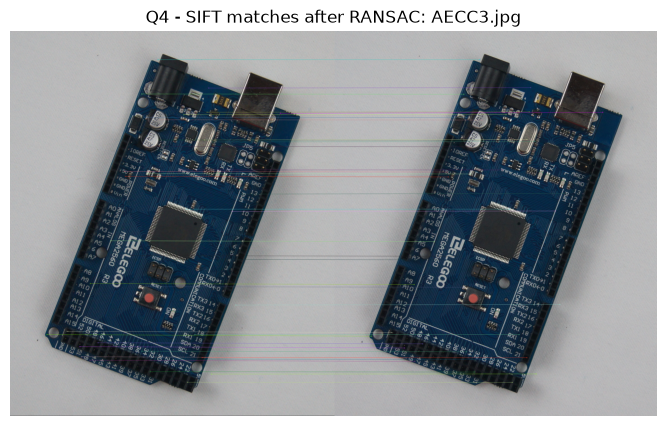

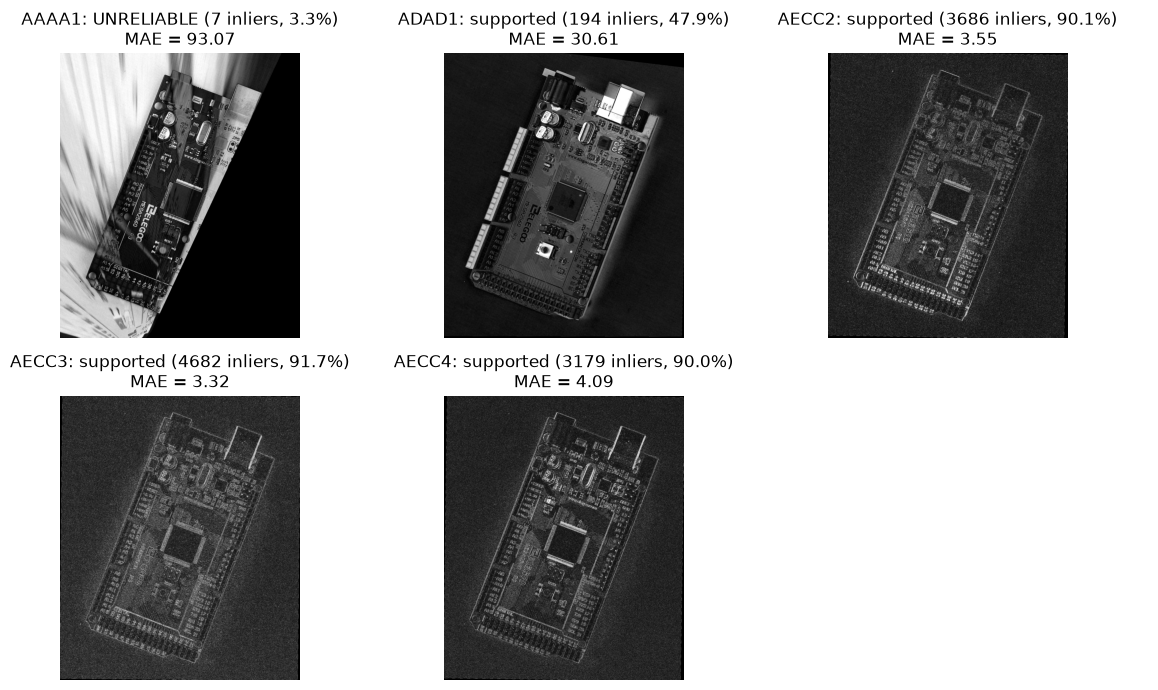

In [26]:

# Q4 - Align the PCB images with AECC1

PCB_DIR = IMAGE_DIR / "pcbs"
template = cv.imread(str(PCB_DIR / "AECC1.jpg"))
if template is None:
    raise FileNotFoundError(f'Could not load PCB template: {PCB_DIR / "AECC1.jpg"}')
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

sift = cv.SIFT_create()
kp_t, des_t = sift.detectAndCompute(template_gray, None)
if des_t is None:
    raise ValueError('No SIFT descriptors found in the template')
matcher = cv.BFMatcher()

pcb_files = [p for p in sorted(PCB_DIR.glob("*.jpg"))
             if p.name != "AECC1.jpg"]
differences = []
match_view = None
best_inlier_count = -1
match_title = ""

for path in pcb_files:
    pcb = cv.imread(str(path))
    if pcb is None:
        print(path.name, '- could not load image')
        continue
    gray = cv.cvtColor(pcb, cv.COLOR_BGR2GRAY)
    kp, des = sift.detectAndCompute(gray, None)
    if des is None or len(des) < 2:
        print(path.name, '- no usable SIFT features')
        continue

    pairs = matcher.knnMatch(des_t, des, k=2)
    good = [m for pair in pairs if len(pair) == 2
            for m, n in [pair] if m.distance < 0.70*n.distance]

    if len(good) < 4:
        print(path.name, "- not enough matches")
        continue

    src = np.float32([kp[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_t[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    H, inliers = cv.findHomography(src, dst, cv.RANSAC, 5.0)

    if H is None or inliers is None or not np.isfinite(H).all():
        print(path.name, "- homography failed")
        continue

    h, w = template.shape[:2]
    aligned = cv.warpPerspective(pcb, H, (w, h))
    valid = cv.warpPerspective(np.full(pcb.shape[:2], 255, np.uint8),
                               H, (w, h), flags=cv.INTER_NEAREST)
    diff = cv.absdiff(template, aligned)
    diff[valid == 0] = 0
    if not np.any(valid > 0):
        print(path.name, '- no valid warped overlap')
        continue
    mae = np.mean(diff[valid > 0])

    count = int(inliers.sum()) if inliers is not None else 0
    ratio = count / len(good)

    reliable = count >= 15 and ratio >= 0.15
    differences.append((path.stem, diff, mae, reliable, count, ratio))
    print(f"{path.name}: {len(good)} matches, "
        f"{count} inliers ({ratio:.1%}), MAE = {mae:.2f}")

    if not reliable:
        print("  Warning: alignment may be unreliable.")

    # Keep one match plot as an example
    
    # Show a small sample of the strongest inlier matches
    if count > best_inlier_count and ratio >= 0.15:
        best_inlier_count = count
        match_title = path.name

        inlier_matches = [
            m for m, keep in zip(good, inliers.ravel()) if keep
        ]
        inlier_matches = sorted(inlier_matches, key=lambda m: m.distance)[:40]

        match_view = cv.drawMatches(
            template, kp_t, pcb, kp, inlier_matches, None,
            flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )


# Show the feature matches
if match_view is not None:
    plt.figure(figsize=(12, 5))
    plt.imshow(cv.cvtColor(match_view, cv.COLOR_BGR2RGB))
    plt.title(f"Q4 - SIFT matches after RANSAC: {match_title}")
    plt.axis("off")
    plt.show()


# Display contrast-enhanced difference images

if differences:
    rows = int(np.ceil(len(differences) / 3))
    fig, axes = plt.subplots(rows, 3, figsize=(12, 3.5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, (name, diff, mae, reliable, count, ratio) in zip(axes, differences):

        # Convert the color difference to grayscale
        gray_diff = cv.cvtColor(diff, cv.COLOR_BGR2GRAY)

        # Ignore zero-valued pixels when selecting the display range
        values = gray_diff[gray_diff > 0]

        if values.size > 0:
            # Use the 99th percentile to limit extreme bright pixels
            upper = max(float(np.percentile(values, 99)), 1.0)

            # Enhance contrast for visualization only
            display_diff = np.clip(
                gray_diff.astype(np.float32) * 255.0 / upper,
                0, 255
            ).astype(np.uint8)
        else:
            display_diff = gray_diff

        ax.imshow(display_diff, cmap="gray", vmin=0, vmax=255)
        status = 'supported' if reliable else 'UNRELIABLE'
        ax.set_title(f'{name}: {status} ({count} inliers, {ratio:.1%})\nMAE = {mae:.2f}')
        ax.axis("off")

    for ax in axes[len(differences):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()



SIFT matching and RANSAC provide the transformation used to align each PCB image with AECC1.jpg. The number of RANSAC inliers and their proportion among the good matches give an indication of how well the matches support the transformation. The difference images show the remaining pixel-level differences after warping.

A low difference can indicate close visual agreement, while a larger difference can come from viewpoint, illumination, shadows, component appearance, or imperfect alignment. A difference image alone does not prove that a PCB has a defect. Any alignment with too few supporting inliers should be treated cautiously.